# 反向探针：给出位置，能读出物体类别吗

**问题：** 之前的探针给物体名、读位置，结果探针按名字找不到物体。这里反过来：告诉探针物体在哪里，让它预测类别名。这样可以区分两种情况：token 里本来就没有类别信息，或者有但按名字检索不到。

**设置**（数据、划分、训练设置与位置探针相同，代码在 `train_reverse.py`）：

- **目标：** 物体的类别，在训练集出现过的类别中做分类（交叉熵）。物体与点提示实验相同：场景中只出现一次的类别，且框中心至少落在一帧画面内。验证集里类别没在训练集出现过的物体不计入。
- **注意力读出（三种 token 都适用）：** 与位置探针相同的 2 层 cross-attention。查询只有物体中心像素的 Plücker 射线（Fourier 编码），不含任何图像特征，所以类别只能来自被读取的 token。
- **直接索引读出（只适用于 DINOv2 和 VGGT）：** 直接取物体中心所在的那一个 patch token，接 MLP 分类。不需要检索，衡量的是这个 token 本身含有多少类别信息。3DRAE 的 token 没有对应的像素位置，做不了这一项。
- **下限：** 训练时把 token 换成其他场景的（只靠射线能猜到的先验），以及永远猜最常见类别。

**怎么读：** top-1 / top-5 是按物体平均的准确率，方括号内为按场景 bootstrap 的 95% 置信区间；macro top-1 是先按类别求准确率再平均，不受常见类别主导。每组一个随机种子。

In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "outputs" / "geo_probe").is_dir())
RUNS = ROOT / "outputs" / "geo_probe"
pd.set_option("display.width", 200)

NAMES = {"3DRAE, attention": "reverse_3drae_real", "DINOv2 patch, attention": "reverse_dino_real",
         "VGGT, attention": "reverse_vggt_real", "DINOv2 patch, index": "reverse_index_dino",
         "VGGT, index": "reverse_index_vggt", "shuffled 3DRAE (floor)": "reverse_3drae_shuffled"}
COLORS = {"3DRAE, attention": "#2a78d6", "DINOv2 patch, attention": "#8a8f98", "VGGT, attention": "#eb6834",
          "DINOv2 patch, index": "#4a4f57", "VGGT, index": "#b23c0c", "shuffled 3DRAE (floor)": "#c8ccd2"}
FREQ = [(1, 9, "1-9"), (10, 49, "10-49"), (50, 199, "50-199"), (200, 10**9, "200+")]


def final(run):
    path = RUNS / run / "final_metrics.json"
    return json.loads(path.read_text()) if path.exists() else None


def objects(run):
    path = RUNS / run / "objects.jsonl"
    if not path.exists():
        return None
    frame = pd.DataFrame([json.loads(line) for line in path.open()])
    frame = frame[frame.train_freq > 0].copy()
    frame["top1"] = [r.top5[0] == r.category for r in frame.itertuples()]
    frame["in_top5"] = [r.category in r.top5 for r in frame.itertuples()]
    return frame


RESULTS = {name: final(run) for name, run in NAMES.items() if final(run)}
rows = {}
for name, result in RESULTS.items():
    e = result["eval_real"]
    row = {key: f"{e[key]['value'] * 100:.1f} [{e[key]['ci95'][0] * 100:.1f}, {e[key]['ci95'][1] * 100:.1f}]"
           for key in ("top1", "top5")}
    row["macro top1"] = f"{e['macro_top1'] * 100:.1f}"
    s = result.get("eval_shuffled")
    row["top1, tokens swapped at eval"] = f"{s['top1']['value'] * 100:.1f}" if s else "-"
    row["n objects"] = e["n"]
    rows[name] = row
any_result = next(iter(RESULTS.values()))
print(f"{any_result['classes']} train categories; always guessing '{any_result['majority_class']}' gives "
      f"top-1 {any_result['majority_top1'] * 100:.1f}%; {any_result['eval_real']['n_unseen_category']} val objects "
      f"of unseen categories left out")
pd.DataFrame(rows).T

195 train categories; always guessing 'door' gives top-1 4.5%; 29 val objects of unseen categories left out


,top1,top5,macro top1,"top1, tokens swapped at eval",n objects
"3DRAE, attention","31.8 [29.1, 34.6]","58.8 [55.5, 62.3]",16.1,8.0,4920
"DINOv2 patch, attention","34.5 [31.8, 37.2]","61.5 [58.4, 65.0]",18.6,9.0,4920
"VGGT, attention","19.3 [17.4, 21.4]","44.2 [41.1, 47.0]",7.8,6.4,4920
"DINOv2 patch, index","56.4 [53.7, 59.0]","78.6 [76.2, 81.1]",40.7,-,4920
"VGGT, index","40.2 [37.3, 42.9]","64.8 [61.6, 67.9]",19.2,-,4920
shuffled 3DRAE (floor),"7.7 [6.7, 8.8]","23.2 [21.2, 25.1]",2.0,7.5,4920


## 1. 总体准确率

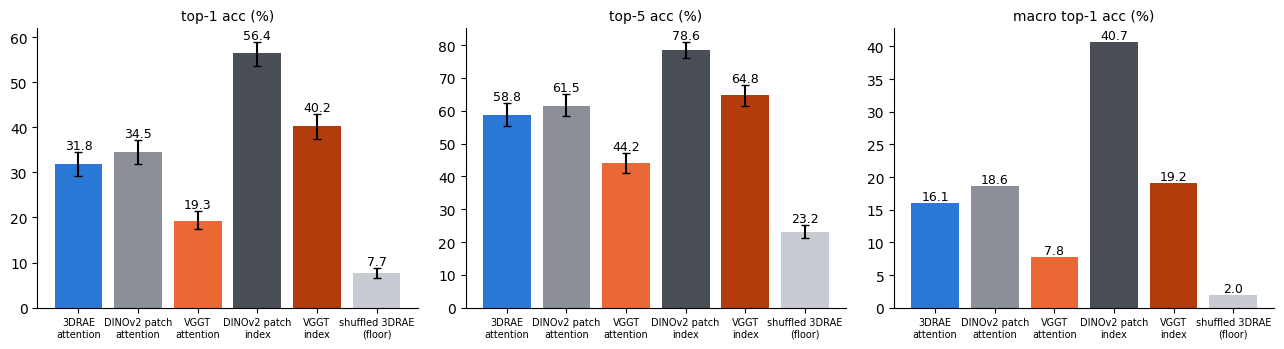

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
names = list(RESULTS)
for ax, key in zip(axes, ("top1", "top5", "macro_top1")):
    e = [RESULTS[n]["eval_real"] for n in names]
    if key == "macro_top1":
        y, err = np.array([m[key] for m in e]) * 100, None
    else:
        y = np.array([m[key]["value"] for m in e]) * 100
        err = np.array([[m[key]["value"] - m[key]["ci95"][0], m[key]["ci95"][1] - m[key]["value"]] for m in e]).T * 100
    ax.bar(range(len(y)), y, yerr=err, color=[COLORS[n] for n in names], capsize=3)
    for i, v in enumerate(y):
        ax.text(i, v + (err[1][i] if err is not None else 0), f"{v:.1f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(range(len(y)), [n.replace(", ", "\n").replace(" (", "\n(") for n in names], fontsize=7)
    ax.set_title({"top1": "top-1 acc (%)", "top5": "top-5 acc (%)", "macro_top1": "macro top-1 acc (%)"}[key], fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 2. 按类别在训练集中的出现次数

,1-9 (n=139),10-49 (n=860),50-199 (n=2925),200+ (n=996)
"3DRAE, attention",0.7,10.5,33.5,49.9
"DINOv2 patch, attention",0.0,14.9,36.3,50.8
"VGGT, attention",0.0,4.3,17.4,40.5
"DINOv2 patch, index",8.6,44.0,59.9,63.8
"VGGT, index",0.0,15.0,43.2,58.7
shuffled 3DRAE (floor),0.0,0.2,4.0,26.1


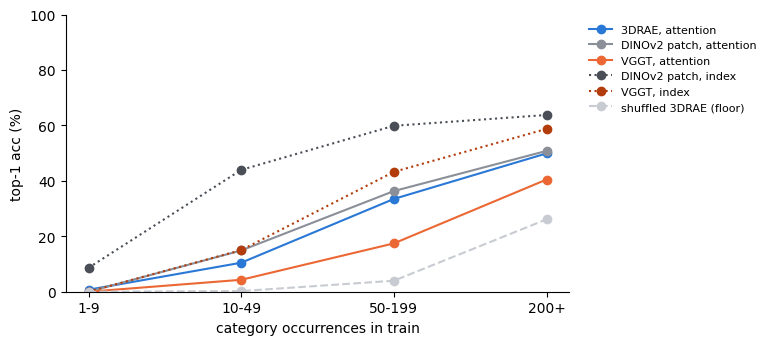

In [3]:
OBJECTS = {name: objects(run) for name, run in NAMES.items() if objects(run) is not None}
table = {}
for name, frame in OBJECTS.items():
    table[name] = {f"{label} (n={((frame.train_freq >= lo) & (frame.train_freq <= hi)).sum()})":
                   frame.top1[(frame.train_freq >= lo) & (frame.train_freq <= hi)].mean() * 100 for lo, hi, label in FREQ}
display(pd.DataFrame(table).T.round(1))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for name, frame in OBJECTS.items():
    y = [frame.top1[(frame.train_freq >= lo) & (frame.train_freq <= hi)].mean() * 100 for lo, hi, _ in FREQ]
    ax.plot(range(len(FREQ)), y, marker="o", color=COLORS[name], label=name,
            linestyle="--" if "shuffled" in name else (":" if "index" in name else "-"))
ax.set_xticks(range(len(FREQ)), [b[2] for b in FREQ])
ax.set_xlabel("category occurrences in train")
ax.set_ylabel("top-1 acc (%)")
ax.set_ylim(0, 100)
ax.legend(fontsize=8, frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 3. 验证集中最常见的 20 个类别的 top-1 准确率（%）

In [4]:
first = next(iter(OBJECTS.values()))
common = first.category.value_counts().head(20)
per_category = pd.DataFrame({name: frame.groupby("category").top1.mean().reindex(common.index) * 100
                             for name, frame in OBJECTS.items()}).round(0)
per_category.insert(0, "n", common.values)
per_category

,n,"3DRAE, attention","DINOv2 patch, attention","VGGT, attention","DINOv2 patch, index","VGGT, index",shuffled 3DRAE (floor)
category,,,,,,,
door,219,47.0,56.0,50.0,57.0,61.0,37.0
bin,195,59.0,57.0,45.0,77.0,70.0,45.0
sink,158,59.0,63.0,45.0,84.0,70.0,8.0
table,150,38.0,39.0,29.0,57.0,44.0,17.0
doorframe,138,36.0,28.0,30.0,35.0,35.0,10.0
socket,137,20.0,26.0,26.0,64.0,60.0,3.0
window,136,59.0,56.0,37.0,68.0,68.0,29.0
toilet,121,69.0,67.0,36.0,84.0,78.0,17.0
shelf,119,23.0,29.0,9.0,55.0,36.0,3.0


## 4. 训练曲线

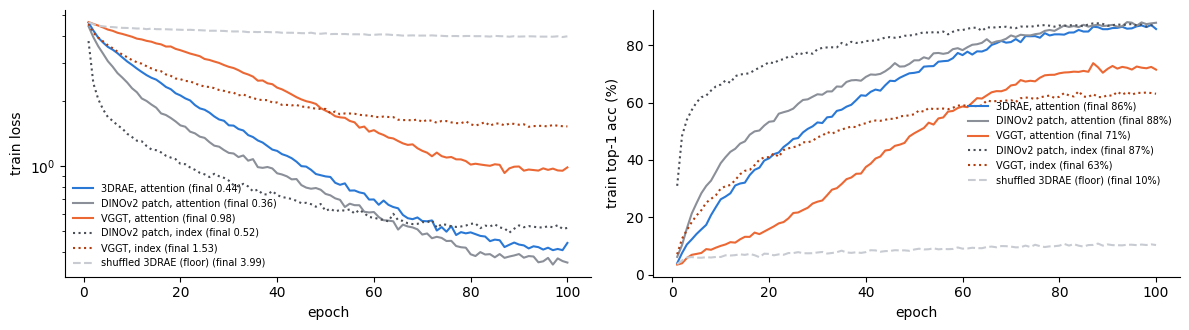

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for name, run in NAMES.items():
    path = RUNS / run / "metrics.jsonl"
    if not path.exists():
        continue
    log = pd.DataFrame([json.loads(line) for line in path.open()]).drop_duplicates("epoch", keep="last")
    style = "--" if "shuffled" in name else (":" if "index" in name else "-")
    axes[0].plot(log.epoch, log.loss, color=COLORS[name], linestyle=style, label=f"{name} (final {log.loss.iloc[-1]:.2f})")
    axes[1].plot(log.epoch, log.train_top1 * 100, color=COLORS[name], linestyle=style,
                 label=f"{name} (final {log.train_top1.iloc[-1] * 100:.0f}%)")
axes[0].set_yscale("log")
for ax, label in zip(axes, ("train loss", "train top-1 acc (%)")):
    ax.set_xlabel("epoch")
    ax.set_ylabel(label)
    ax.legend(fontsize=7, frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 5. 结论

任务 12620–12625。验证集 4920 个物体，195 个类别；永远猜最常见类别（door）的 top-1 是 4.5%。

| | top-1 | top-5 | macro top-1 | 训练集 top-1 |
|---|---|---|---|---|
| 3DRAE，注意力读出 | 31.8% [29.1, 34.6] | 58.8% | 16.1% | 86% |
| DINOv2 patch，注意力读出 | 34.5% [31.8, 37.2] | 61.5% | 18.6% | 88% |
| VGGT，注意力读出 | 19.3% [17.4, 21.4] | 44.2% | 7.8% | 71% |
| DINOv2 patch，直接索引 | 56.4% [53.7, 59.0] | 78.6% | 40.7% | 87% |
| VGGT，直接索引 | 40.2% [37.3, 42.9] | 64.8% | 19.2% | 63% |
| 打乱的 3DRAE（下限） | 7.7% | 23.2% | 2.0% | 10% |

**1. 3DRAE 的 token 里有类别信息，而且和 DINOv2 patch 一样多（在同样的读法下）。** 只给一条射线，探针从 3DRAE token 读出类别的 top-1 是 31.8%，DINOv2 patch 是 34.5%，置信区间重叠，都远高于下限 7.7%。把 token 换成别的场景后掉到 8%–9%，说明信息确实来自场景 token。neck 把 2816 个 patch 压成 1024 个 token，没有明显丢掉“某个位置是什么物体”的信息。

**2. 但这个信息只对常见类别可用。** 出现 200 次以上的类别，3DRAE 的 top-1 是 50%；50–199 次是 34%；10–49 次只有 10%；少于 10 次接近 0。macro top-1 只有 16%。这和位置探针的结果一致：那边也是常见类别误差 0.65 m，少见类别 1.3 m 以上。

**3. 所有探针都严重过拟合。** 训练集 top-1 在 86%–88%，验证集只有 32%–35%。913 个场景、约 8,800 个物体不足以学会 195 个类别的“名字 ↔ 视觉特征”对应，尤其是少见类别。这才是“名称提示找不到物体”的主要原因：DINOv2 特征没有和语言对齐，这个对应关系只能从这点标注里现学。

**4. 用注意力按位置检索，会损失一部分信息。** 同样是 DINOv2 patch，直接取物体中心那个 patch 是 56.4%，用射线做注意力检索只有 34.5%。所以 3DRAE 的 31.8% 是这种读法的下界，不代表 token 里只有这么多。3DRAE 的 token 没有像素位置，做不了直接索引，无法测它的上限。

**5. VGGT 的类别信息明显更少。** 直接索引 40.2% 对 DINOv2 的 56.4%，注意力读出 19.3% 对 34.5%。这解释了上一个实验里 VGGT 在名称提示下接近下限：它的 token 几何好，但类别信息弱。

**对主线的含义**
- 回答最初的问题：两种情况都有。类别信息在 3DRAE token 里是有的（常见类别），不是 neck 丢了；但少见类别基本读不出来，原因是标注数据太少，而不是检索方式。
- 所以提高“点和名称对应”的能力，重点是语言对齐的来源，有两条路：
  - 换成自带语言对齐的特征或文本端（例如 dino.txt 的文本编码器，对齐的就是 DINOv2 的 patch 特征），不依赖这 913 个场景去现学。
  - 大幅增加带物体标注的数据。
- 直接索引的 56% 也不高，说明即使是 DINOv2 的单个 patch，在 195 类上也有不少认不出（box、paper、cabinet 这类外观不固定的物体最差）。物体中心的像素有时落在遮挡物上，这部分是标注方式带来的噪声。

**注意事项**
- 每组一个随机种子。
- 只在训练集出现过的类别里分类，是封闭集；不能说明对没见过的类别的能力。
- 物体中心投影处不一定能看到该物体（被遮挡，或中心在物体内部空处），所有方法都受同样影响。
- 注意力读出里 patch 一侧的射线只经过线性层，定位精度有限；这可能是注意力读出低于直接索引的部分原因。
